In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

d = pd.read_csv("../data/model_table.csv")
cols = ["TR", "FR", "SR"]

def leave_one_fire_out(data, min_rows=30):
    rows = []
    for fire in data["fire"].unique():
        train = data[data["fire"] != fire]
        test = data[data["fire"] == fire]
        # AUC needs both outcomes, and tiny fires give noisy scores
        if len(test) < min_rows or test["Response"].nunique() < 2:
            continue
        model = sm.Logit(train["Response"], sm.add_constant(train[cols])).fit(disp=0)
        p = model.predict(sm.add_constant(test[cols], has_constant="add"))
        rows.append({"fire": fire, "state": test["state"].iloc[0], "n_rows": len(test),
                     "debris_flows": int(test["Response"].sum()),
                     "auc": roc_auc_score(test["Response"], p)})
    return pd.DataFrame(rows).sort_values("auc")

all_fires = leave_one_fire_out(d)
print(all_fires.round(2).to_string(index=False))
print("median AUC, all states:", round(all_fires["auc"].median(), 3), "across", len(all_fires), "fires")

ca = leave_one_fire_out(d[d["state"] == "CA"])
print("median AUC, California only:", round(ca["auc"].median(), 3), "across", len(ca), "fires")

                      fire state  n_rows  debris_flows  auc
              Cameron Peak    CO      30            20 0.42
               Little Bear    NM      47            30 0.56
          East Troublesome    CO      64            11 0.59
              Waldo Canyon    CO      31             7 0.64
                     Dolan    CA     118            41 0.65
          Grand Prix - Old    CA      78            60 0.70
               Horseshoe 2    AZ      30             4 0.70
               Cub Creek 2    WA      95            18 0.78
                 Coal Seam    CO     145            17 0.81
                 Gladiator    AZ      35             3 0.81
                    Thomas    CA     857           171 0.81
                   Station    CA     489           108 0.82
Hermits Peak - Calf Canyon    NM     162            15 0.84
                       Elk    WY     180            15 0.84
                     Butte    CA     123             7 0.90
Fish (San Gabriel Complex)    CA     241

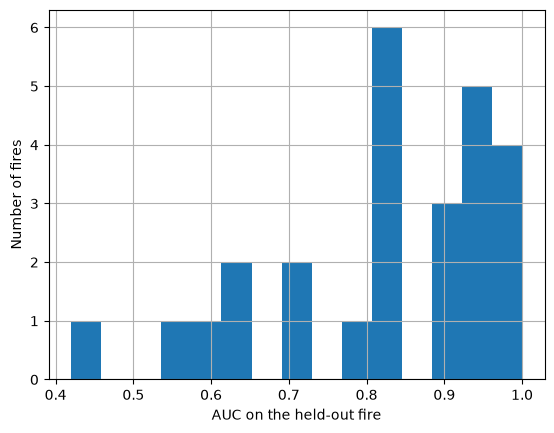

In [2]:
all_fires["auc"].hist(bins=15)
plt.xlabel("AUC on the held-out fire")
plt.ylabel("Number of fires")
plt.savefig("../notes/loo_auc.png", dpi=150)
plt.show()